In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('student_performance_dataset.csv')

In [3]:
df.head()

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
0,S147,Male,31,68.267841,86,High School,Yes,Yes,63,Pass
1,S136,Male,16,78.222927,73,PhD,No,No,50,Fail
2,S209,Female,21,87.525096,74,PhD,Yes,No,55,Fail
3,S458,Female,27,92.076483,99,Bachelors,No,No,65,Pass
4,S078,Female,37,98.655517,63,Masters,No,Yes,70,Pass


# EDA

In [4]:
df.shape

(708, 10)

In [5]:
df=df.drop(columns=['Student_ID','Final_Exam_Score'])

In [6]:
df.shape

(708, 8)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 708 entries, 0 to 707
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      708 non-null    object 
 1   Study_Hours_per_Week        708 non-null    int64  
 2   Attendance_Rate             708 non-null    float64
 3   Past_Exam_Scores            708 non-null    int64  
 4   Parental_Education_Level    708 non-null    object 
 5   Internet_Access_at_Home     708 non-null    object 
 6   Extracurricular_Activities  708 non-null    object 
 7   Pass_Fail                   708 non-null    object 
dtypes: float64(1), int64(2), object(5)
memory usage: 44.4+ KB


In [8]:
df.describe()

,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores
count,708.000000,708.000000,708.000000
mean,26.132768,78.107722,77.871469
std,8.877727,13.802802,14.402739
min,10.000000,50.116970,50.000000
25%,19.000000,67.550094,65.000000
50%,27.000000,79.363046,79.000000
75%,34.000000,89.504232,91.000000
max,39.000000,99.967675,100.000000


In [9]:
df.isnull().sum()

Gender                        0
Study_Hours_per_Week          0
Attendance_Rate               0
Past_Exam_Scores              0
Parental_Education_Level      0
Internet_Access_at_Home       0
Extracurricular_Activities    0
Pass_Fail                     0
dtype: int64

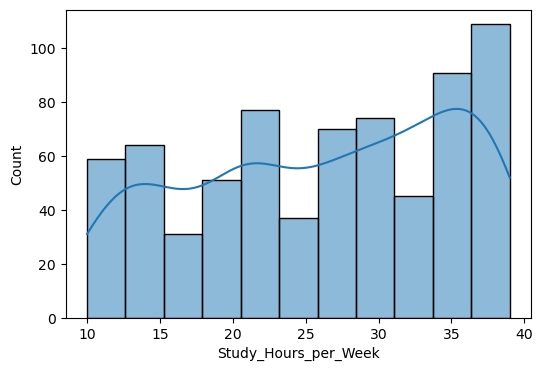

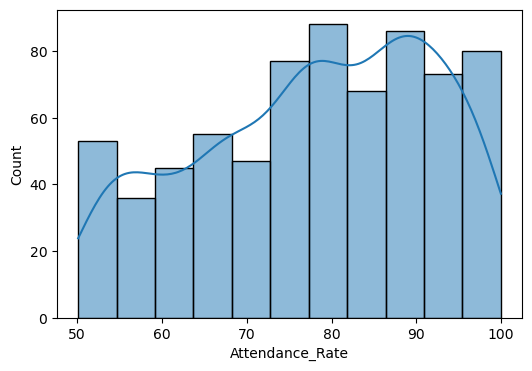

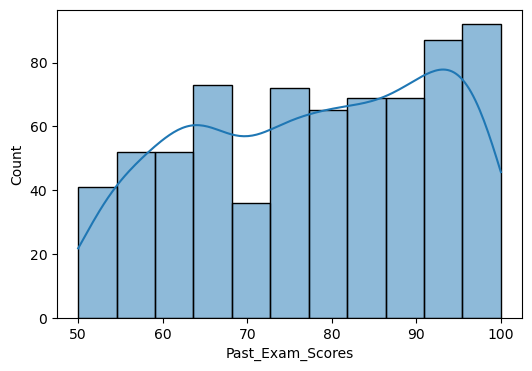

In [10]:
column_list=['Study_Hours_per_Week','Attendance_Rate','Past_Exam_Scores']
for col in column_list:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde=True)

<Axes: >

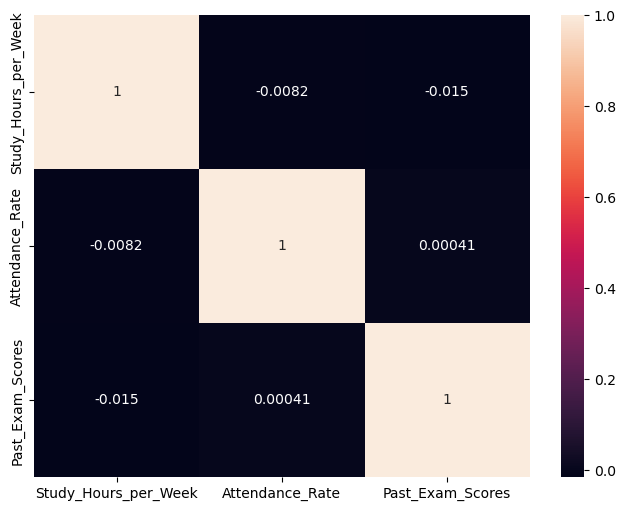

In [11]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

# Data cleaning

In [12]:
df.dtypes

Gender                         object
Study_Hours_per_Week            int64
Attendance_Rate               float64
Past_Exam_Scores                int64
Parental_Education_Level       object
Internet_Access_at_Home        object
Extracurricular_Activities     object
Pass_Fail                      object
dtype: object

In [13]:
df=df.drop_duplicates()

In [14]:
df.shape

(500, 8)

# Data Preprocessing

In [15]:
df.head()

,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Pass_Fail
0,Male,31,68.267841,86,High School,Yes,Yes,Pass
1,Male,16,78.222927,73,PhD,No,No,Fail
2,Female,21,87.525096,74,PhD,Yes,No,Fail
3,Female,27,92.076483,99,Bachelors,No,No,Pass
4,Female,37,98.655517,63,Masters,No,Yes,Pass


In [16]:
df["Gender"] = df["Gender"].map({
    "Male": 0,
    "Female": 1
})

df["Internet_Access_at_Home"] = df["Internet_Access_at_Home"].map({
    "No": 0,
    "Yes": 1
})

df["Extracurricular_Activities"] = df["Extracurricular_Activities"].map({
    "No": 0,
    "Yes": 1
})

df["Pass_Fail"] = df["Pass_Fail"].map({
    "Fail": 0,
    "Pass": 1
})

In [17]:
df.head()

,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Pass_Fail
0,0,31,68.267841,86,High School,1,1,1
1,0,16,78.222927,73,PhD,0,0,0
2,1,21,87.525096,74,PhD,1,0,0
3,1,27,92.076483,99,Bachelors,0,0,1
4,1,37,98.655517,63,Masters,0,1,1


In [18]:
df=pd.get_dummies(df,columns=['Parental_Education_Level'],drop_first=True)

In [19]:
df=df.astype(int)

In [20]:
df.head()

,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Internet_Access_at_Home,Extracurricular_Activities,Pass_Fail,Parental_Education_Level_High School,Parental_Education_Level_Masters,Parental_Education_Level_PhD
0,0,31,68,86,1,1,1,1,0,0
1,0,16,78,73,0,0,0,0,0,1
2,1,21,87,74,1,0,0,0,0,1
3,1,27,92,99,0,0,1,0,0,0
4,1,37,98,63,0,1,1,0,1,0


In [21]:
# Feature Engineering

In [22]:
from sklearn.preprocessing import StandardScaler
cols=['Study_Hours_per_Week','Attendance_Rate','Past_Exam_Scores']
scale=StandardScaler()
df[cols]=scale.fit_transform(df[cols])

In [23]:
df.head()

,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Internet_Access_at_Home,Extracurricular_Activities,Pass_Fail,Parental_Education_Level_High School,Parental_Education_Level_Masters,Parental_Education_Level_PhD
0,0,0.661242,-0.525419,0.747277,1,1,1,1,0,0
1,0,-1.044161,0.192366,-0.153725,0,0,0,0,0,1
2,1,-0.475694,0.838373,-0.084417,1,0,0,0,0,1
3,1,0.206467,1.197265,1.648278,0,0,1,0,0,0
4,1,1.343403,1.627936,-0.846803,0,1,1,0,1,0


In [24]:
x=df.drop(columns='Pass_Fail',axis=1)
y=df['Pass_Fail']

In [25]:
# Train-Test-Split

In [26]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [27]:
# Apply Models

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,f1_score

In [29]:
models={
    'lg':LogisticRegression(),
    'dt':DecisionTreeClassifier(),
    'gb':GaussianNB(),
    'svc':SVC(),
    'knn':KNeighborsClassifier(),
    'rf':RandomForestClassifier()
}

In [30]:
results=[]

In [31]:
for name,model in models.items():
    model.fit(x_train,y_train)
    y_pred=model.predict(x_test)
    acc=accuracy_score(y_test,y_pred)
    f1=f1_score(y_test,y_pred)
    results.append({
        'Model':name,
        'accuracy':round(acc,4),
        'F1_score':round(f1,4)
    })

In [32]:
results

[{'Model': 'lg', 'accuracy': 0.84, 'F1_score': 0.68},
 {'Model': 'dt', 'accuracy': 0.72, 'F1_score': 0.5172},
 {'Model': 'gb', 'accuracy': 0.83, 'F1_score': 0.6047},
 {'Model': 'svc', 'accuracy': 0.83, 'F1_score': 0.6383},
 {'Model': 'knn', 'accuracy': 0.76, 'F1_score': 0.5385},
 {'Model': 'rf', 'accuracy': 0.84, 'F1_score': 0.68}]

In [33]:
# Adaboost

In [34]:
from sklearn.ensemble import AdaBoostClassifier
ada=AdaBoostClassifier(n_estimators=100,random_state=42)
ada.fit(x_train,y_train)
ada_pred=ada.predict(x_test)
print(accuracy_score(y_test,ada_pred))


0.83


In [35]:
# GradientBoosting

In [36]:
from sklearn.ensemble import GradientBoostingClassifier
gb=GradientBoostingClassifier(n_estimators=100,learning_rate=0.1,random_state=42)
gb.fit(x_train,y_train)
gb_pred=gb.predict(x_test)
print(accuracy_score(y_test,gb_pred))

0.8


In [37]:
# XGBoosting

In [38]:
from xgboost import XGBClassifier
xg=XGBClassifier(n_estimator=100,max_lepth=3,learning_rate=0.1,random_state=42)
xg.fit(x_train,y_train)
xg_pred=xg.predict(x_test)
print(accuracy_score(y_test,xg_pred))

c:\Users\Home\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [19:16:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "max_lepth", "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


0.79


In [39]:
import joblib
import os

# Trained SVC model
svc_model = models['svc']

# Model aur preprocessing information save karna
joblib.dump({
    'model': svc_model,
    'scaler': scale,
    'feature_columns': list(x.columns)
}, 'student_model.pkl')

print("File saved at:", os.path.abspath('student_model.pkl'))

File saved at: c:\Student Performance\student_model.pkl
